# Diabetes Readmission Dataset: Exploratory Data Analysis

This notebook explores the UCI Diabetes 130-US Hospitals dataset (1999-2008). It is descriptive EDA, not a diagnostic tool, clinical evaluation, or model-training notebook.

The target is hospital readmission: `<30` is the positive class for the planned 30-day task; `>30` and `NO` are grouped as negative. Patient and encounter identifiers are excluded from feature analyses. No missing-value imputation or outlier removal is performed.

The raw source is kept unchanged. In this notebook only the literal `?` is parsed as missing; the dataset's literal `None` test-result category is preserved. Figures are written to `reports/figures/`. See `data/raw/diabetes/DATASET.md` for source, citation, license, and limitations.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

DATA_RELATIVE = Path("data/raw/diabetes/source/diabetic_data.csv")
PROJECT_ROOT = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / DATA_RELATIVE).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Could not locate {DATA_RELATIVE} from {Path.cwd()}")

DATA_PATH = PROJECT_ROOT / DATA_RELATIVE
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=["?"], low_memory=False)
ID_COLUMNS = ["encounter_id", "patient_nbr"]
TARGET_COLUMN = "readmitted"
NUMERIC_FEATURES = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses",
]
missing_columns = [column for column in ID_COLUMNS + [TARGET_COLUMN] + NUMERIC_FEATURES if column not in df]
if missing_columns:
    raise ValueError(f"Expected source columns are missing: {missing_columns}")

eda_df = df.assign(readmitted_30d=df[TARGET_COLUMN].eq("<30").astype("int8"))
print(f"Source: {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Shape: {df.shape[0]:,} encounters x {df.shape[1]} columns")
print(f"Unique patients: {df['patient_nbr'].nunique():,}")
print(f"Duplicate encounter IDs: {df['encounter_id'].duplicated().sum():,}")
print(f"Figures: {FIGURE_DIR.relative_to(PROJECT_ROOT)}")

Source: data\raw\diabetes\source\diabetic_data.csv
Shape: 101,766 encounters x 50 columns
Unique patients: 71,518
Duplicate encounter IDs: 0
Figures: reports\figures


## Dataset Overview And Types
The CSV contains identifiers and a target in addition to the 47 UCI features. Coded IDs are not treated as continuous measurements. The `None` strings in test-result columns are source categories, not missing values.

In [2]:
overview = pd.DataFrame({
    "value": [
        len(df), df.shape[1], df["encounter_id"].nunique(),
        df["patient_nbr"].nunique(), df["encounter_id"].duplicated().sum(),
    ]
}, index=["encounters", "CSV columns", "unique encounter IDs", "unique patients", "duplicate encounter IDs"])
display(overview)

dtype_summary = df.dtypes.astype(str).value_counts().rename_axis("pandas dtype").to_frame("column count")
display(dtype_summary)
display(df.dtypes.rename("dtype").to_frame().T)

,value
encounters,101766
CSV columns,50
unique encounter IDs,101766
unique patients,71518
duplicate encounter IDs,0


,column count
pandas dtype,
object,37
int64,13


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
dtype,int64,int64,object,object,object,object,int64,int64,int64,int64,...,object,object,object,object,object,object,object,object,object,object


## Missing Values
Only `?` was converted to missing. The heatmap-style bar chart reports missing cells by column; it does not imply that missingness is random or justify dropping rows.

,missing rows,share
weight,98569,96.86%
medical_specialty,49949,49.08%
payer_code,40256,39.56%
race,2273,2.23%
diag_3,1423,1.40%
diag_2,358,0.35%
diag_1,21,0.02%


Literal 'None' category counts (not parsed as NA): {'max_glu_serum': 96420, 'A1Cresult': 84748}


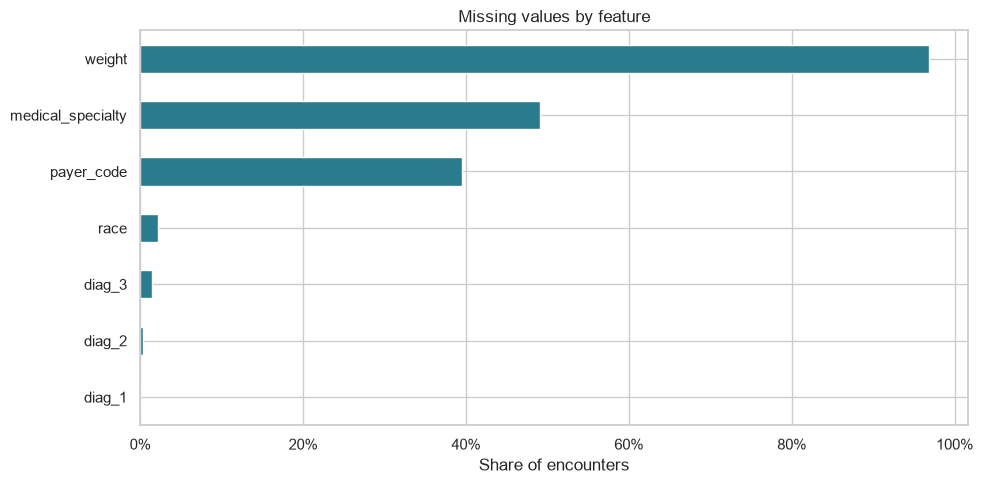

In [3]:
missing_summary = (
    df.isna().sum().rename("missing rows").to_frame()
    .assign(share=lambda table: table["missing rows"] / len(df))
    .query("`missing rows` > 0").sort_values("missing rows", ascending=False)
)
display(missing_summary.style.format({"share": "{:.2%}"}))

none_category_counts = {
    column: int(df[column].eq("None").sum())
    for column in ["max_glu_serum", "A1Cresult"]
}
print("Literal 'None' category counts (not parsed as NA):", none_category_counts)

if not missing_summary.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    missing_summary["share"].sort_values().plot.barh(ax=ax, color="#287c8e")
    ax.set(title="Missing values by feature", xlabel="Share of encounters", ylabel="")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "diabetes_missingness.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## Target Distribution And Class Imbalance
The original three labels are shown alongside the planned binary task. The observed class ratio describes this dataset only; it is not an individual risk estimate.

,encounters,share
readmitted,,
NO,54864,53.91%
>30,35545,34.93%
<30,11357,11.16%


Positive (<30) share: 11.16%
Negative-to-positive count ratio: 7.96:1


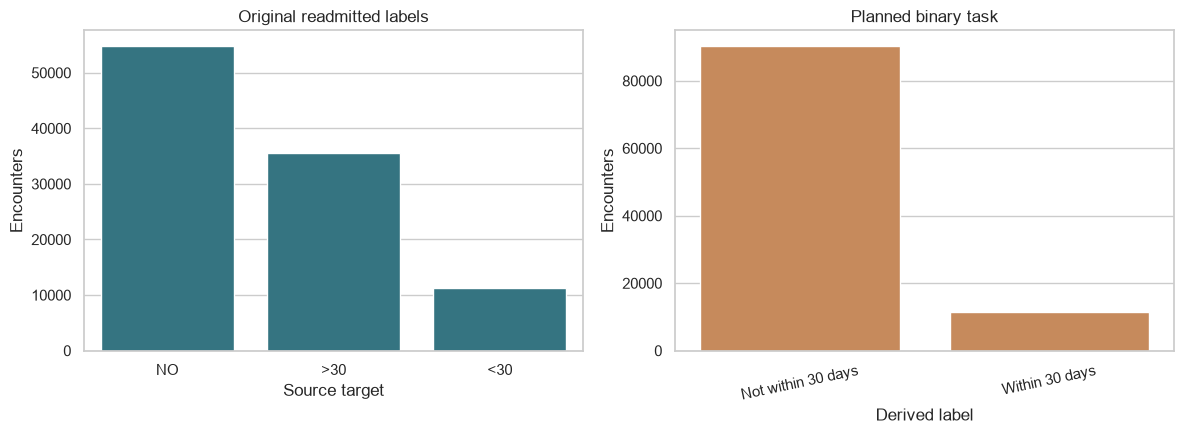

In [4]:
target_counts = df[TARGET_COLUMN].value_counts().reindex(["NO", ">30", "<30"], fill_value=0)
target_summary = pd.DataFrame({"encounters": target_counts, "share": target_counts / len(df)})
display(target_summary.style.format({"share": "{:.2%}"}))

binary_counts = eda_df["readmitted_30d"].value_counts().reindex([0, 1], fill_value=0)
positive_share = float(binary_counts.loc[1] / binary_counts.sum())
imbalance_ratio = float(binary_counts.loc[0] / binary_counts.loc[1])
print(f"Positive (<30) share: {positive_share:.2%}")
print(f"Negative-to-positive count ratio: {imbalance_ratio:.2f}:1")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=df, x=TARGET_COLUMN, order=["NO", ">30", "<30"], color="#287c8e", ax=axes[0])
axes[0].set(title="Original readmitted labels", xlabel="Source target", ylabel="Encounters")
sns.barplot(x=["Not within 30 days", "Within 30 days"], y=[binary_counts.loc[0], binary_counts.loc[1]], color="#d8874a", ax=axes[1])
axes[1].set(title="Planned binary task", xlabel="Derived label", ylabel="Encounters")
axes[1].tick_params(axis="x", rotation=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "diabetes_target_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## Feature Distributions
The numeric plots cover count/duration variables only. Admission, discharge, and source codes are categorical identifiers and are not given a continuous numeric interpretation.

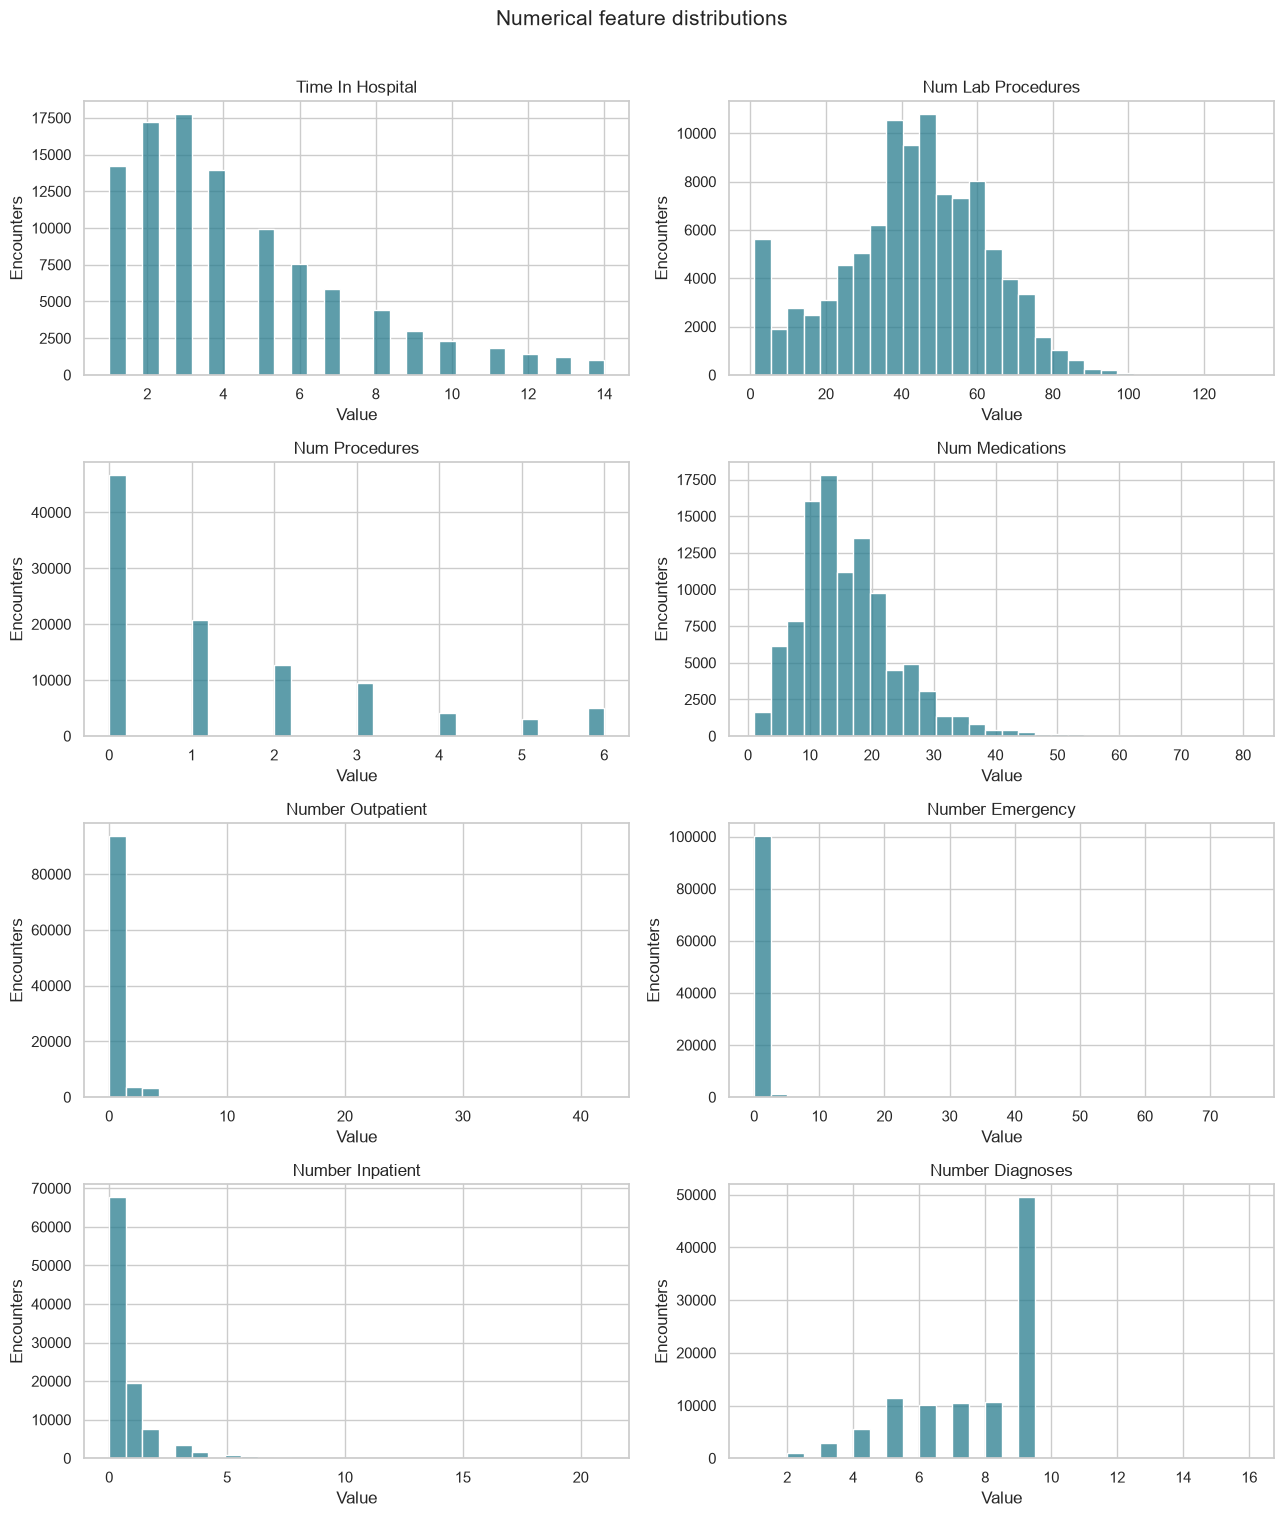

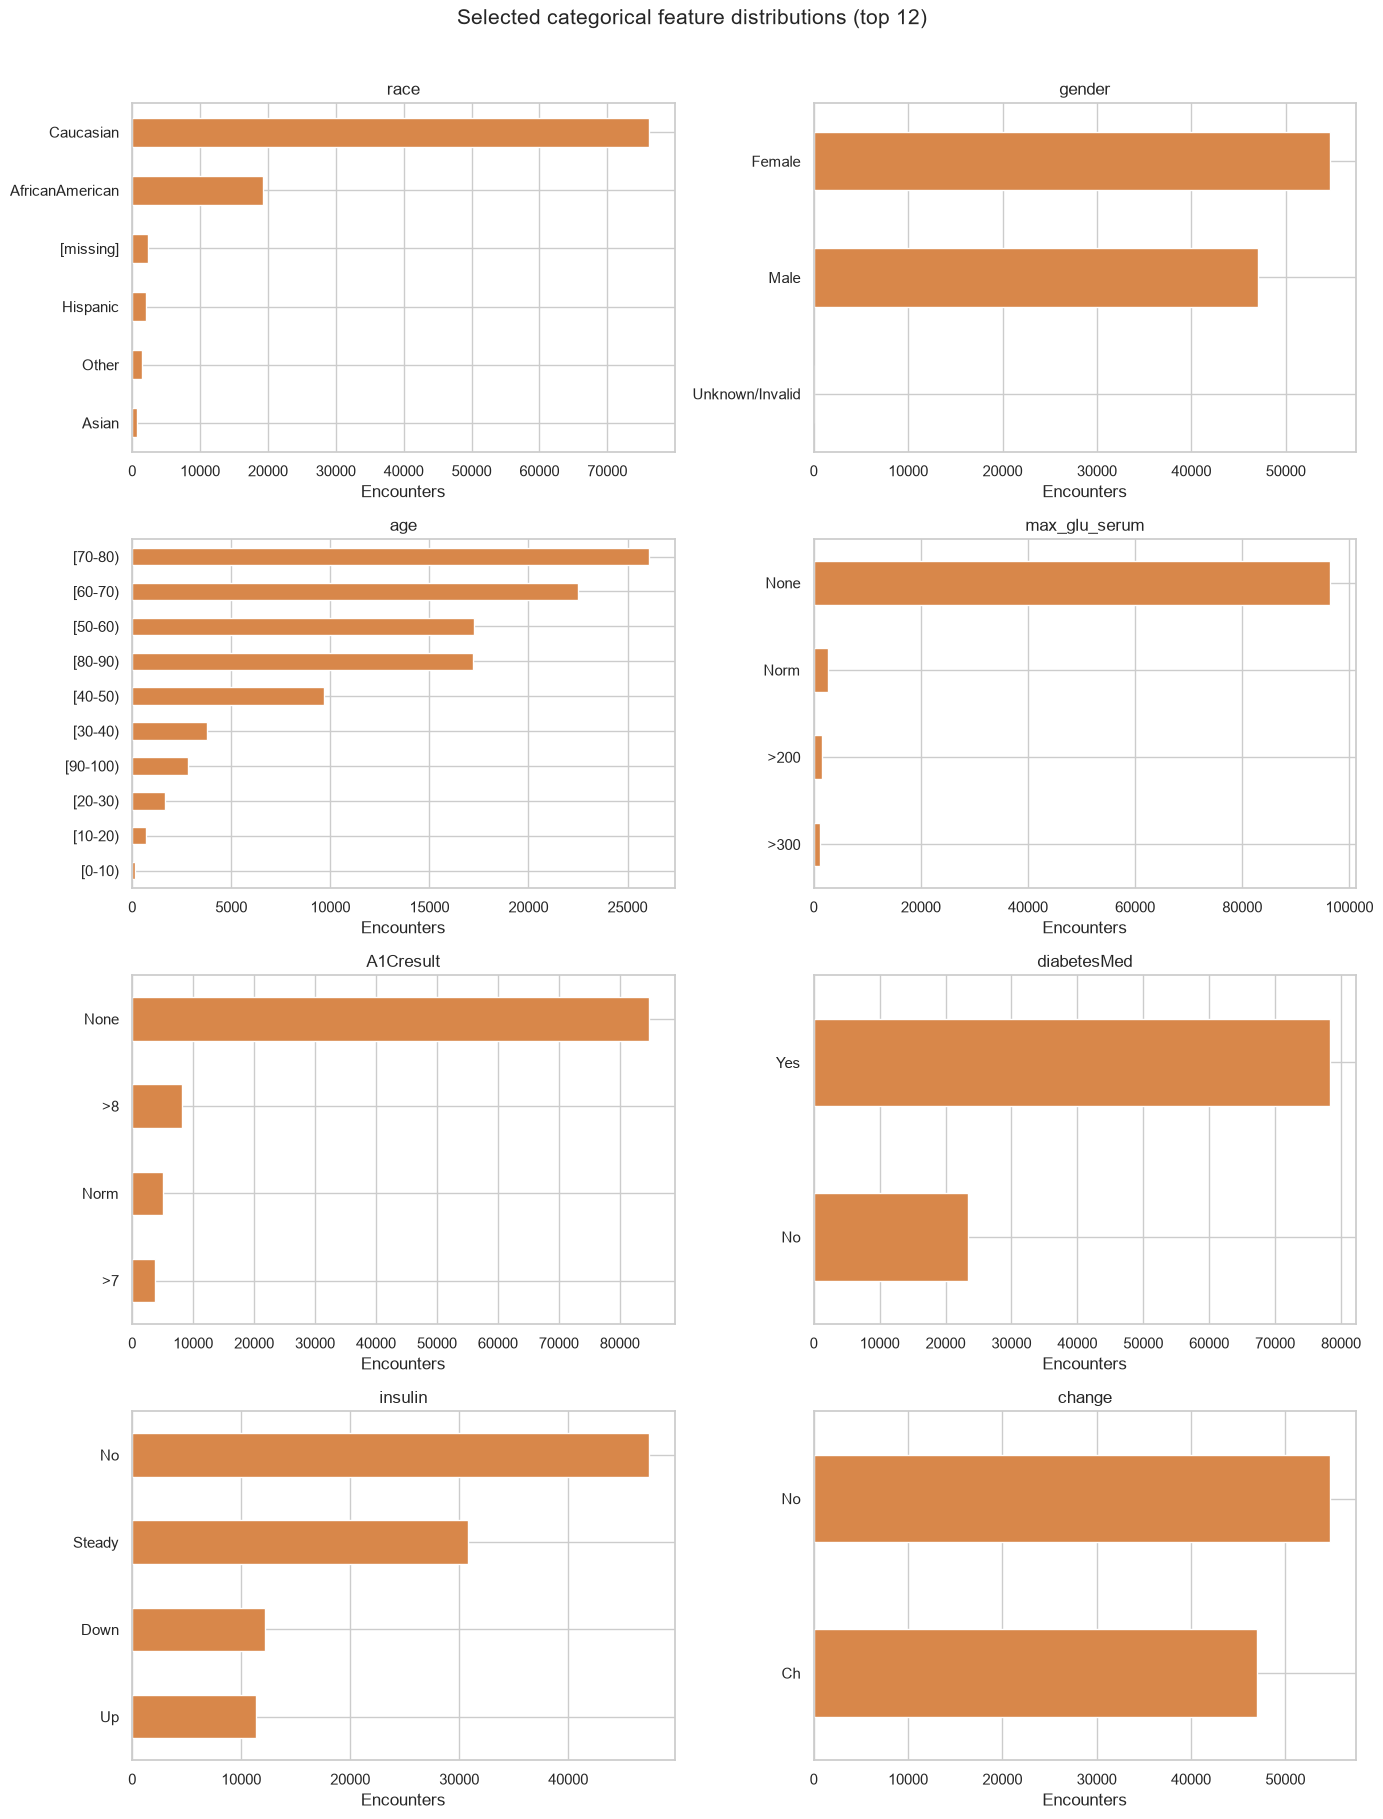

In [5]:
numeric_data = df[NUMERIC_FEATURES].apply(pd.to_numeric, errors="coerce")
fig, axes = plt.subplots(4, 2, figsize=(13, 15))
for column, ax in zip(NUMERIC_FEATURES, axes.flat):
    sns.histplot(numeric_data[column].dropna(), bins=30, ax=ax, color="#287c8e")
    ax.set(title=column.replace("_", " ").title(), xlabel="Value", ylabel="Encounters")
fig.suptitle("Numerical feature distributions", y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "diabetes_numeric_distributions.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

CATEGORICAL_PLOT_FEATURES = ["race", "gender", "age", "max_glu_serum", "A1Cresult", "diabetesMed", "insulin", "change"]
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for column, ax in zip(CATEGORICAL_PLOT_FEATURES, axes.flat):
    values = df[column].astype("string").fillna("[missing]")
    counts = values.value_counts(dropna=False).head(12).sort_values()
    counts.plot.barh(ax=ax, color="#d8874a")
    ax.set(title=column, xlabel="Encounters", ylabel="")
fig.suptitle("Selected categorical feature distributions (top 12)", y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "diabetes_categorical_distributions.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## Correlation And Outlier Analysis
Correlation is limited to the selected numeric count/duration fields. The IQR table flags distribution tails for review only; it does not identify invalid measurements and no rows are removed.

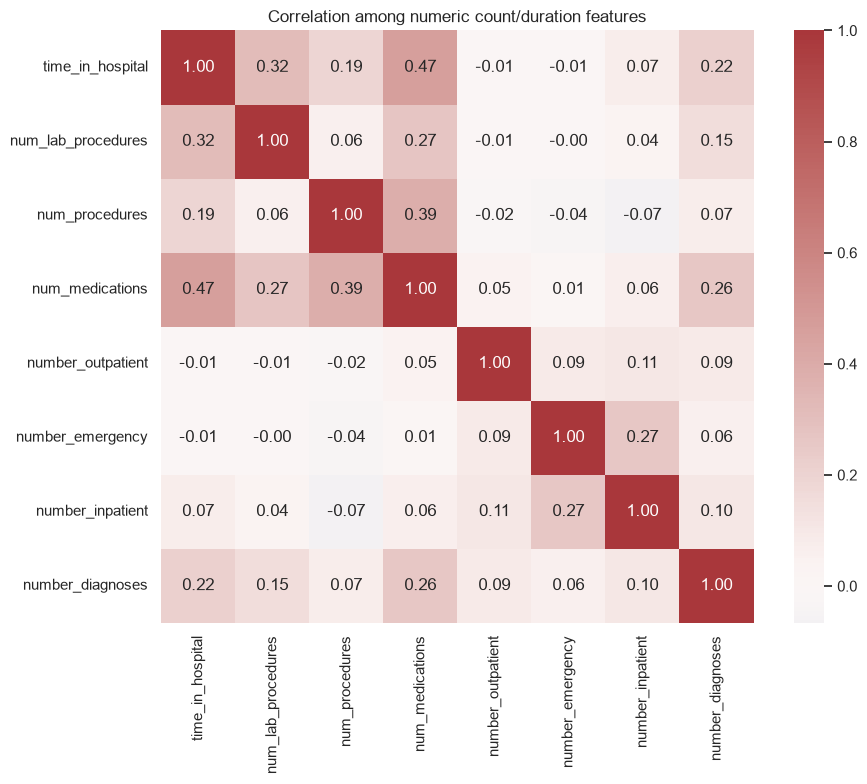

,lower_fence,upper_fence,IQR flag count,share of nonmissing
feature,,,,
number_outpatient,0.00,0.00,16739,16.45%
number_emergency,0.00,0.00,11383,11.19%
number_inpatient,-1.50,2.50,7049,6.93%
num_procedures,-3.00,5.00,4954,4.87%
num_medications,-5.00,35.00,2557,2.51%
time_in_hospital,-4.00,12.00,2252,2.21%
number_diagnoses,1.50,13.50,281,0.28%
num_lab_procedures,-8.00,96.00,143,0.14%


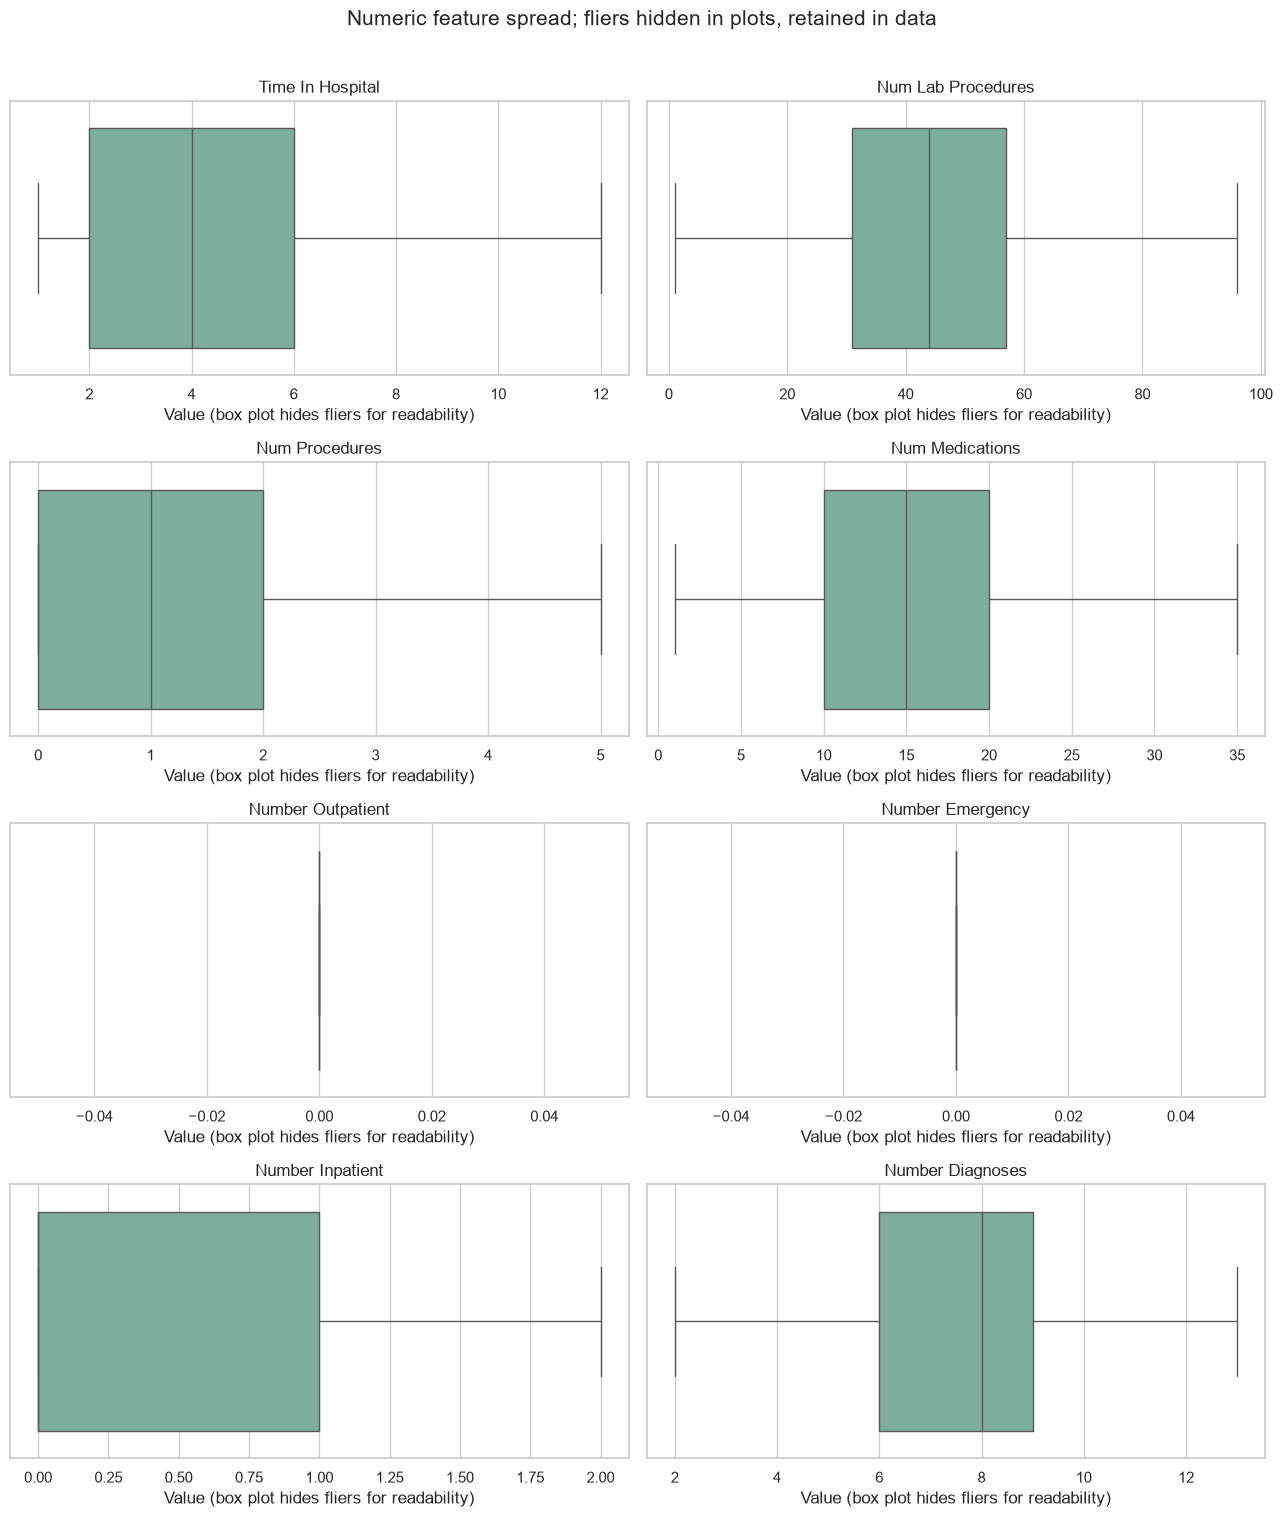

In [6]:
correlation = numeric_data.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation, cmap="vlag", center=0, annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Correlation among numeric count/duration features")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "diabetes_numeric_correlation.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

outlier_rows = []
for column in NUMERIC_FEATURES:
    values = numeric_data[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({"feature": column, "lower_fence": lower, "upper_fence": upper, "IQR flag count": count, "share of nonmissing": count / len(values)})
outlier_summary = pd.DataFrame(outlier_rows).set_index("feature").sort_values("share of nonmissing", ascending=False)
display(outlier_summary.style.format({"lower_fence": "{:.2f}", "upper_fence": "{:.2f}", "share of nonmissing": "{:.2%}"}))

fig, axes = plt.subplots(4, 2, figsize=(13, 15))
for column, ax in zip(NUMERIC_FEATURES, axes.flat):
    sns.boxplot(x=numeric_data[column], showfliers=False, ax=ax, color="#72b7a1")
    ax.set(title=column.replace("_", " ").title(), xlabel="Value (box plot hides fliers for readability)")
fig.suptitle("Numeric feature spread; fliers hidden in plots, retained in data", y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "diabetes_numeric_outliers.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## Feature-Target Relationships
These plots compare observed records grouped by the derived label. They are descriptive associations, not causal effects or calibrated individual probabilities. Numeric boxplots use a reproducible sample for rendering speed; grouped categorical rates use all records.

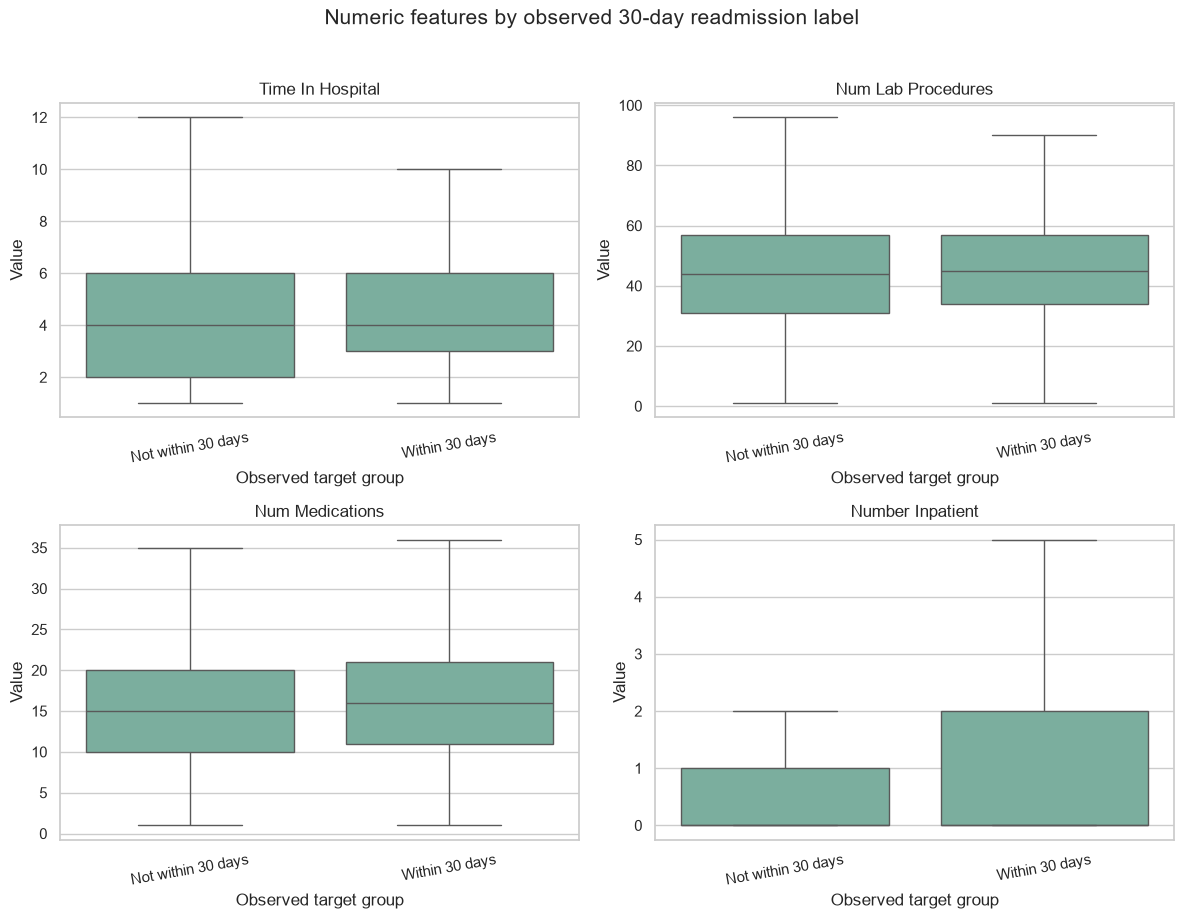

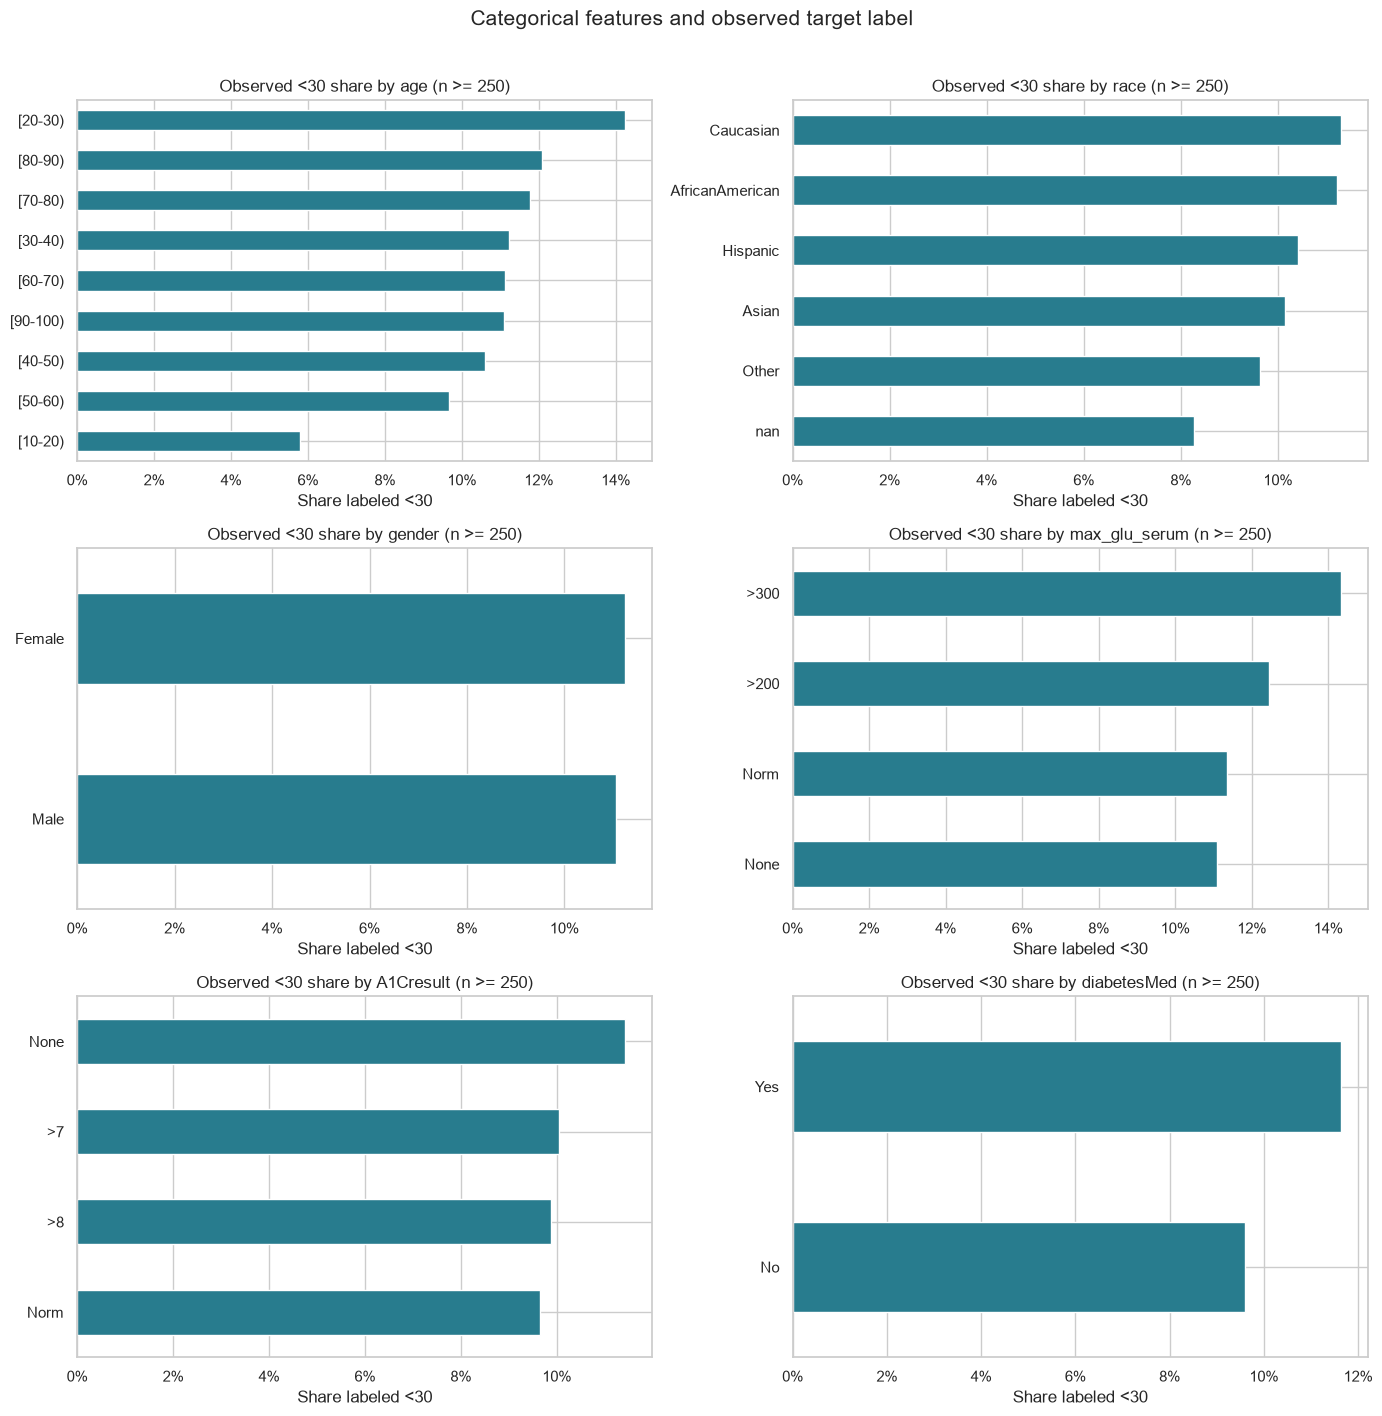

In [7]:
NUMERIC_RELATION_FEATURES = ["time_in_hospital", "num_lab_procedures", "num_medications", "number_inpatient"]
plot_data = eda_df[NUMERIC_RELATION_FEATURES + ["readmitted_30d"]].copy()
plot_data["readmission group"] = plot_data["readmitted_30d"].map({0: "Not within 30 days", 1: "Within 30 days"})
plot_sample = plot_data.sample(n=min(20000, len(plot_data)), random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for column, ax in zip(NUMERIC_RELATION_FEATURES, axes.flat):
    sns.boxplot(data=plot_sample, x="readmission group", y=column, showfliers=False, ax=ax, color="#72b7a1")
    ax.set(title=column.replace("_", " ").title(), xlabel="Observed target group", ylabel="Value")
    ax.tick_params(axis="x", rotation=10)
fig.suptitle("Numeric features by observed 30-day readmission label", y=1.02, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "diabetes_numeric_target_relationships.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

CATEGORICAL_RELATION_FEATURES = ["age", "race", "gender", "max_glu_serum", "A1Cresult", "diabetesMed"]
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
for column, ax in zip(CATEGORICAL_RELATION_FEATURES, axes.flat):
    relation = (
        eda_df.groupby(column, dropna=False)["readmitted_30d"]
        .agg(["mean", "size"]).rename(columns={"mean": "observed share", "size": "encounters"})
        .query("encounters >= 250").sort_values("observed share", ascending=True).tail(12)
    )
    relation["observed share"].plot.barh(ax=ax, color="#287c8e")
    ax.set(title=f"Observed <30 share by {column} (n >= 250)", xlabel="Share labeled <30", ylabel="")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
fig.suptitle("Categorical features and observed target label", y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "diabetes_categorical_target_relationships.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## Interpretation And Limitations

The dataset is historical inpatient encounter data from 130 US hospitals (1999-2008), restricted to encounters involving patients already diagnosed with diabetes. Repeated encounters mean that patient-aware splits are important in later modeling. Missingness, especially in weight, is substantial, and the recorded features may not all be available at every proposed prediction time.

All patterns here describe this dataset and label transformation only. Associations are not causes, the binary label combines `>30` and `NO`, and these exploratory plots do not demonstrate clinical effectiveness or produce medical advice. No values were imputed, no outliers were removed, and no model was trained.

In [8]:
if not missing_summary.empty:
    highest_missing = missing_summary["share"].idxmax()
    highest_missing_share = missing_summary.loc[highest_missing, "share"]
else:
    highest_missing, highest_missing_share = "none", 0.0
print(f"EDA summary: {len(df):,} encounters; {df['patient_nbr'].nunique():,} unique patients.")
print(f"Observed <30 label share: {positive_share:.2%} ({binary_counts.loc[1]:,} encounters).")
print(f"Highest missingness: {highest_missing} ({highest_missing_share:.2%}).")
print("Interpretation: dataset-specific descriptive statistics only; not diagnosis, causation, or clinical evidence.")

EDA summary: 101,766 encounters; 71,518 unique patients.
Observed <30 label share: 11.16% (11,357 encounters).
Highest missingness: weight (96.86%).
Interpretation: dataset-specific descriptive statistics only; not diagnosis, causation, or clinical evidence.
